## CÀI ĐẶT & KÉO DATASET SẠCH TỪ HUGGING FACE HUB

In [1]:
# ==============================================================================
# CELL 1: CÀI ĐẶT & KÉO DATASET SẠCH TỪ HUGGING FACE HUB
# ==============================================================================
# !pip install -q lightgbm prophet scikit-learn joblib huggingface_hub pandas numpy matplotlib

import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from huggingface_hub import hf_hub_download, HfApi, login
from google.colab import userdata
warnings.filterwarnings("ignore")

# HF_TOKEN = os.getenv("HF_TOKEN", "hf_YOUR_HUGGINGFACE_WRITE_TOKEN")
HF_TOKEN = userdata.get('HF_TOKEN')
HF_DATASET_REPO = "cuongduongok/yt-trend-forecaster-gold-data"
HF_MODEL_REPO = "cuongduongok/yt-trend-forecaster-models"

# Tải dữ liệu Gold từ Hugging Face (hoặc đọc từ local nếu vừa chạy xong file 01)
local_fallback = "gold_output/gold_topic_timeseries.parquet"
if os.path.exists(local_fallback):
    data_path = local_fallback
    print("📂 Đọc dữ liệu Gold từ thư mục local...")
else:
    print("☁️ Đang tải dữ liệu Gold từ Hugging Face Dataset Hub...")
    data_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename="gold_topic_timeseries.parquet", repo_type="dataset")

df_raw = pd.read_parquet(data_path)
df_raw["ds"] = pd.to_datetime(df_raw["ds"])
print(f"✅ Đã tải {len(df_raw):,} dòng dữ liệu của {df_raw['topic_name'].nunique()} chủ đề.")
df_raw.head()

☁️ Đang tải dữ liệu Gold từ Hugging Face Dataset Hub...


gold_topic_timeseries.parquet: reconstructing file:   0%|          |  0.00B / 2.39MB            

gold_topic_timeseries.parquet: downloading bytes:           |  0.00B            

✅ Đã tải 80,726 dòng dữ liệu của 116 chủ đề.


,ds,topic_name,topic_type,total_views,total_likes,total_comments,trending_video_count,total_country_appearances,engagement_rate
0,2024-10-12,Autos & Vehicles,CATEGORY,62670000,2634696,158124,81,183,0.044564
1,2024-10-13,Autos & Vehicles,CATEGORY,61494957,2564864,158784,84,179,0.044291
2,2024-10-14,Autos & Vehicles,CATEGORY,65036177,2677800,158520,83,177,0.043611
3,2024-10-15,Autos & Vehicles,CATEGORY,68684609,2839793,170984,91,184,0.043835
4,2024-10-16,Autos & Vehicles,CATEGORY,71842351,3046086,185907,90,180,0.044987


## TIỀN XỬ LÝ CHUỖI THỜI GIAN LIÊN TỤC & KỸ THUẬT ĐẶC TRƯNG (FEATURE ENGINEERING)

In [2]:
# ==============================================================================
# CELL 2: TIỀN XỬ LÝ CHUỖI THỜI GIAN LIÊN TỤC & KỸ THUẬT ĐẶC TRƯNG (FEATURE ENGINEERING)
# ==============================================================================
# 1. Điền đầy các ngày bị khuyết (Reindex Continuous Daily Grid) để tránh đứt gãy cửa sổ trượt
def make_continuous_timeseries(df: pd.DataFrame) -> pd.DataFrame:
    full_dfs = []
    for (t_type, t_name), group in df.groupby(["topic_type", "topic_name"]):
        group = group.sort_values("ds").drop_duplicates("ds")
        if len(group) < 45:  # Bỏ qua chủ đề có lịch sử quá ngắn (< 45 ngày)
            continue
        idx = pd.date_range(group["ds"].min(), group["ds"].max(), freq="D")
        group = group.set_index("ds").reindex(idx).reset_index().rename(columns={"index": "ds"})
        group["topic_type"] = t_type
        group["topic_name"] = t_name
        # Nội suy mượt cho những ngày khuyết nhẹ, điền 0 cho các cột đếm
        for col in ["total_views", "total_likes", "total_comments", "trending_video_count", "total_country_appearances", "engagement_rate"]:
            group[col] = group[col].interpolate(method="linear", limit=3).fillna(0)
        full_dfs.append(group)
    return pd.concat(full_dfs, ignore_index=True)

df_continuous = make_continuous_timeseries(df_raw)

# Mã hóa ID cho từng chủ đề (Category Encoding)
topic_list = sorted(df_continuous["topic_name"].unique())
topic_to_id = {name: idx for idx, name in enumerate(topic_list)}
df_continuous["topic_id"] = df_continuous["topic_name"].map(topic_to_id)

# 2. Hàm tạo đặc trưng Cửa sổ trượt (Sliding Window) + Sóng lượng giác Fourier
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(["topic_name", "ds"]).copy()

    # Biến đổi Log1p để ổn định phương sai của lượt xem (từ vài chục nghìn đến hàng trăm triệu)
    df["log_views"] = np.log1p(df["total_views"])

    g = df.groupby("topic_name")["log_views"]
    g_vid = df.groupby("topic_name")["trending_video_count"]

    # Đặc trưng độ trễ (Lag Features)
    for lag in [1, 2, 3, 7, 14, 21, 30]:
        df[f"lag_{lag}"] = g.shift(lag)

    # Đặc trưng thống kê cửa sổ trượt (Rolling Window Statistics - tính từ t-1 trở về trước)
    shifted = g.shift(1)
    df["rolling_mean_7"] = shifted.rolling(7).mean()
    df["rolling_std_7"] = shifted.rolling(7).std().fillna(0)
    df["rolling_mean_14"] = shifted.rolling(14).mean()
    df["rolling_mean_30"] = shifted.rolling(30).mean()
    df["rolling_max_7"] = shifted.rolling(7).max()

    # Độ dốc / Vận tốc tăng trưởng (Momentum & Acceleration)
    df["velocity_3d"] = df["lag_1"] - df["lag_3"]
    df["momentum_ratio_7_30"] = df["rolling_mean_7"] - df["rolling_mean_30"]
    df["video_supply_lag_1"] = g_vid.shift(1)

    # Đặc trưng Chu kỳ Thời gian & Biến đổi miền tần số (Fourier Terms)
    df["day_of_week"] = df["ds"].dt.dayofweek
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
    day_of_year = df["ds"].dt.dayofyear

    # Sóng Sin/Cos chu kỳ tuần (7 ngày) và năm (365.25 ngày)
    df["sin_week"] = np.sin(2 * np.pi * df["day_of_week"] / 7.0)
    df["cos_week"] = np.cos(2 * np.pi * df["day_of_week"] / 7.0)
    df["sin_year"] = np.sin(2 * np.pi * day_of_year / 365.25)
    df["cos_year"] = np.cos(2 * np.pi * day_of_year / 365.25)

    return df

df_feat = build_features(df_continuous).dropna().reset_index(drop=True)

FEATURE_COLS = [
    "topic_id", "lag_1", "lag_2", "lag_3", "lag_7", "lag_14", "lag_21", "lag_30",
    "rolling_mean_7", "rolling_std_7", "rolling_mean_14", "rolling_mean_30", "rolling_max_7",
    "velocity_3d", "momentum_ratio_7_30", "video_supply_lag_1",
    "day_of_week", "is_weekend", "sin_week", "cos_week", "sin_year", "cos_year"
]

print(f"✅ Hoàn tất tạo {len(FEATURE_COLS)} đặc trưng! Dữ liệu sẵn sàng huấn luyện: {len(df_feat):,} mẫu.")

✅ Hoàn tất tạo 22 đặc trưng! Dữ liệu sẵn sàng huấn luyện: 80,218 mẫu.


## CHIA TẬP DỮ LIỆU THEO THỜI GIAN (TIME-BASED SPLIT) & HUẤN LUYỆN LIGHTGBM

In [3]:
# ==============================================================================
# CELL 3: CHIA TẬP DỮ LIỆU THEO THỜI GIAN (TIME-BASED SPLIT) & HUẤN LUYỆN LIGHTGBM
# ==============================================================================
# Lấy 14 ngày cuối cùng làm tập Kiểm thử (Test Horizon = 14 ngày)
cutoff_date = df_feat["ds"].max() - pd.Timedelta(days=14)

train_df = df_feat[df_feat["ds"] <= cutoff_date]
test_df = df_feat[df_feat["ds"] > cutoff_date]

X_train, y_train = train_df[FEATURE_COLS], train_df["log_views"]
X_test, y_test = test_df[FEATURE_COLS], test_df["log_views"]

print(f"📅 Cutoff Date: {cutoff_date.strftime('%Y-%m-%d')} | Train samples: {len(train_df):,} | Test samples: {len(test_df):,}")

# Huấn luyện mô hình LightGBM Regressor
lgb_model = lgb.LGBMRegressor(
    objective="regression_l1", # Tối ưu trực tiếp MAE để kháng nhiễu (Outliers)
    n_estimators=1200,
    learning_rate=0.03,
    num_leaves=31,
    subsample_for_bin=50000,
    colsample_bytree=0.8,
    subsample=0.8,
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    categorical_feature=["topic_id"],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=100)]
)

📅 Cutoff Date: 2026-10-05 | Train samples: 78,622 | Test samples: 1,596
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.066162 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4465
[LightGBM] [Info] Number of data points in the train set: 78622, number of used features: 22
[LightGBM] [Info] Start training from score 16.544765
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[279]	valid_0's l1: 0.121215


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, n_estimators=1200,
              n_jobs=-1, objective='regression_l1', random_state=42,
              subsample=0.8, subsample_for_bin=50000)

### ĐO ĐẠC KẾT QUẢ (MAE, RMSE, MAPE & PEAK TIMING ERROR)

In [4]:
# ==============================================================================
# CELL 4: ĐO ĐẠC KẾT QUẢ (MAE, RMSE, MAPE & PEAK TIMING ERROR)
# ==============================================================================
# Dự báo trên tập Test và đổi ngược từ hàm Log1p về số Lượt xem thực tế (expm1)
test_df = test_df.copy()
test_df["pred_log_views"] = lgb_model.predict(X_test)
test_df["pred_views"] = np.expm1(np.maximum(0, test_df["pred_log_views"]))
test_df["actual_views"] = test_df["total_views"]

# 1. Các chỉ số sai số chuẩn trên toàn tập Test
mae_views = mean_absolute_error(test_df["actual_views"], test_df["pred_views"])
rmse_views = np.sqrt(mean_squared_error(test_df["actual_views"], test_df["pred_views"]))
# Chỉ tính MAPE trên các dòng có view thực tế > 0 để tránh chia cho 0
valid_mask = test_df["actual_views"] > 1000
mape_score = mean_absolute_percentage_error(test_df.loc[valid_mask, "actual_views"], test_df.loc[valid_mask, "pred_views"]) * 100

# 2. Đo Peak Timing Error (Sai số ngày đạt đỉnh của từng chủ đề trong 14 ngày Test)
peak_errors = []
for topic, grp in test_df.groupby("topic_name"):
    actual_peak_date = grp.loc[grp["actual_views"].idxmax(), "ds"]
    pred_peak_date = grp.loc[grp["pred_views"].idxmax(), "ds"]
    peak_errors.append(abs((actual_peak_date - pred_peak_date).days))

mean_peak_day_error = np.mean(peak_errors)

print("=" * 65)
print("📊 BẢNG KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ BÁO (TEST HORIZON = 14 NGÀY)")
print("=" * 65)
print(f"🔹 MAE  (Sai số tuyệt đối TB)      : {mae_views:,.0f} views")
print(f"🔹 RMSE (Sai số bình phương căn)   : {rmse_views:,.0f} views")
print(f"🔹 MAPE (Tỷ lệ sai số phần trăm)   : {mape_score:.2f}%")
print(f"🔹 Peak Timing Error (Lệch ngày đỉnh): ± {mean_peak_day_error:.2f} ngày")
print("=" * 65)

📊 BẢNG KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ BÁO (TEST HORIZON = 14 NGÀY)
🔹 MAE  (Sai số tuyệt đối TB)      : 4,745,122 views
🔹 RMSE (Sai số bình phương căn)   : 16,884,786 views
🔹 MAPE (Tỷ lệ sai số phần trăm)   : 17.09%
🔹 Peak Timing Error (Lệch ngày đỉnh): ± 2.22 ngày


### Một số biểu đồ trực quan

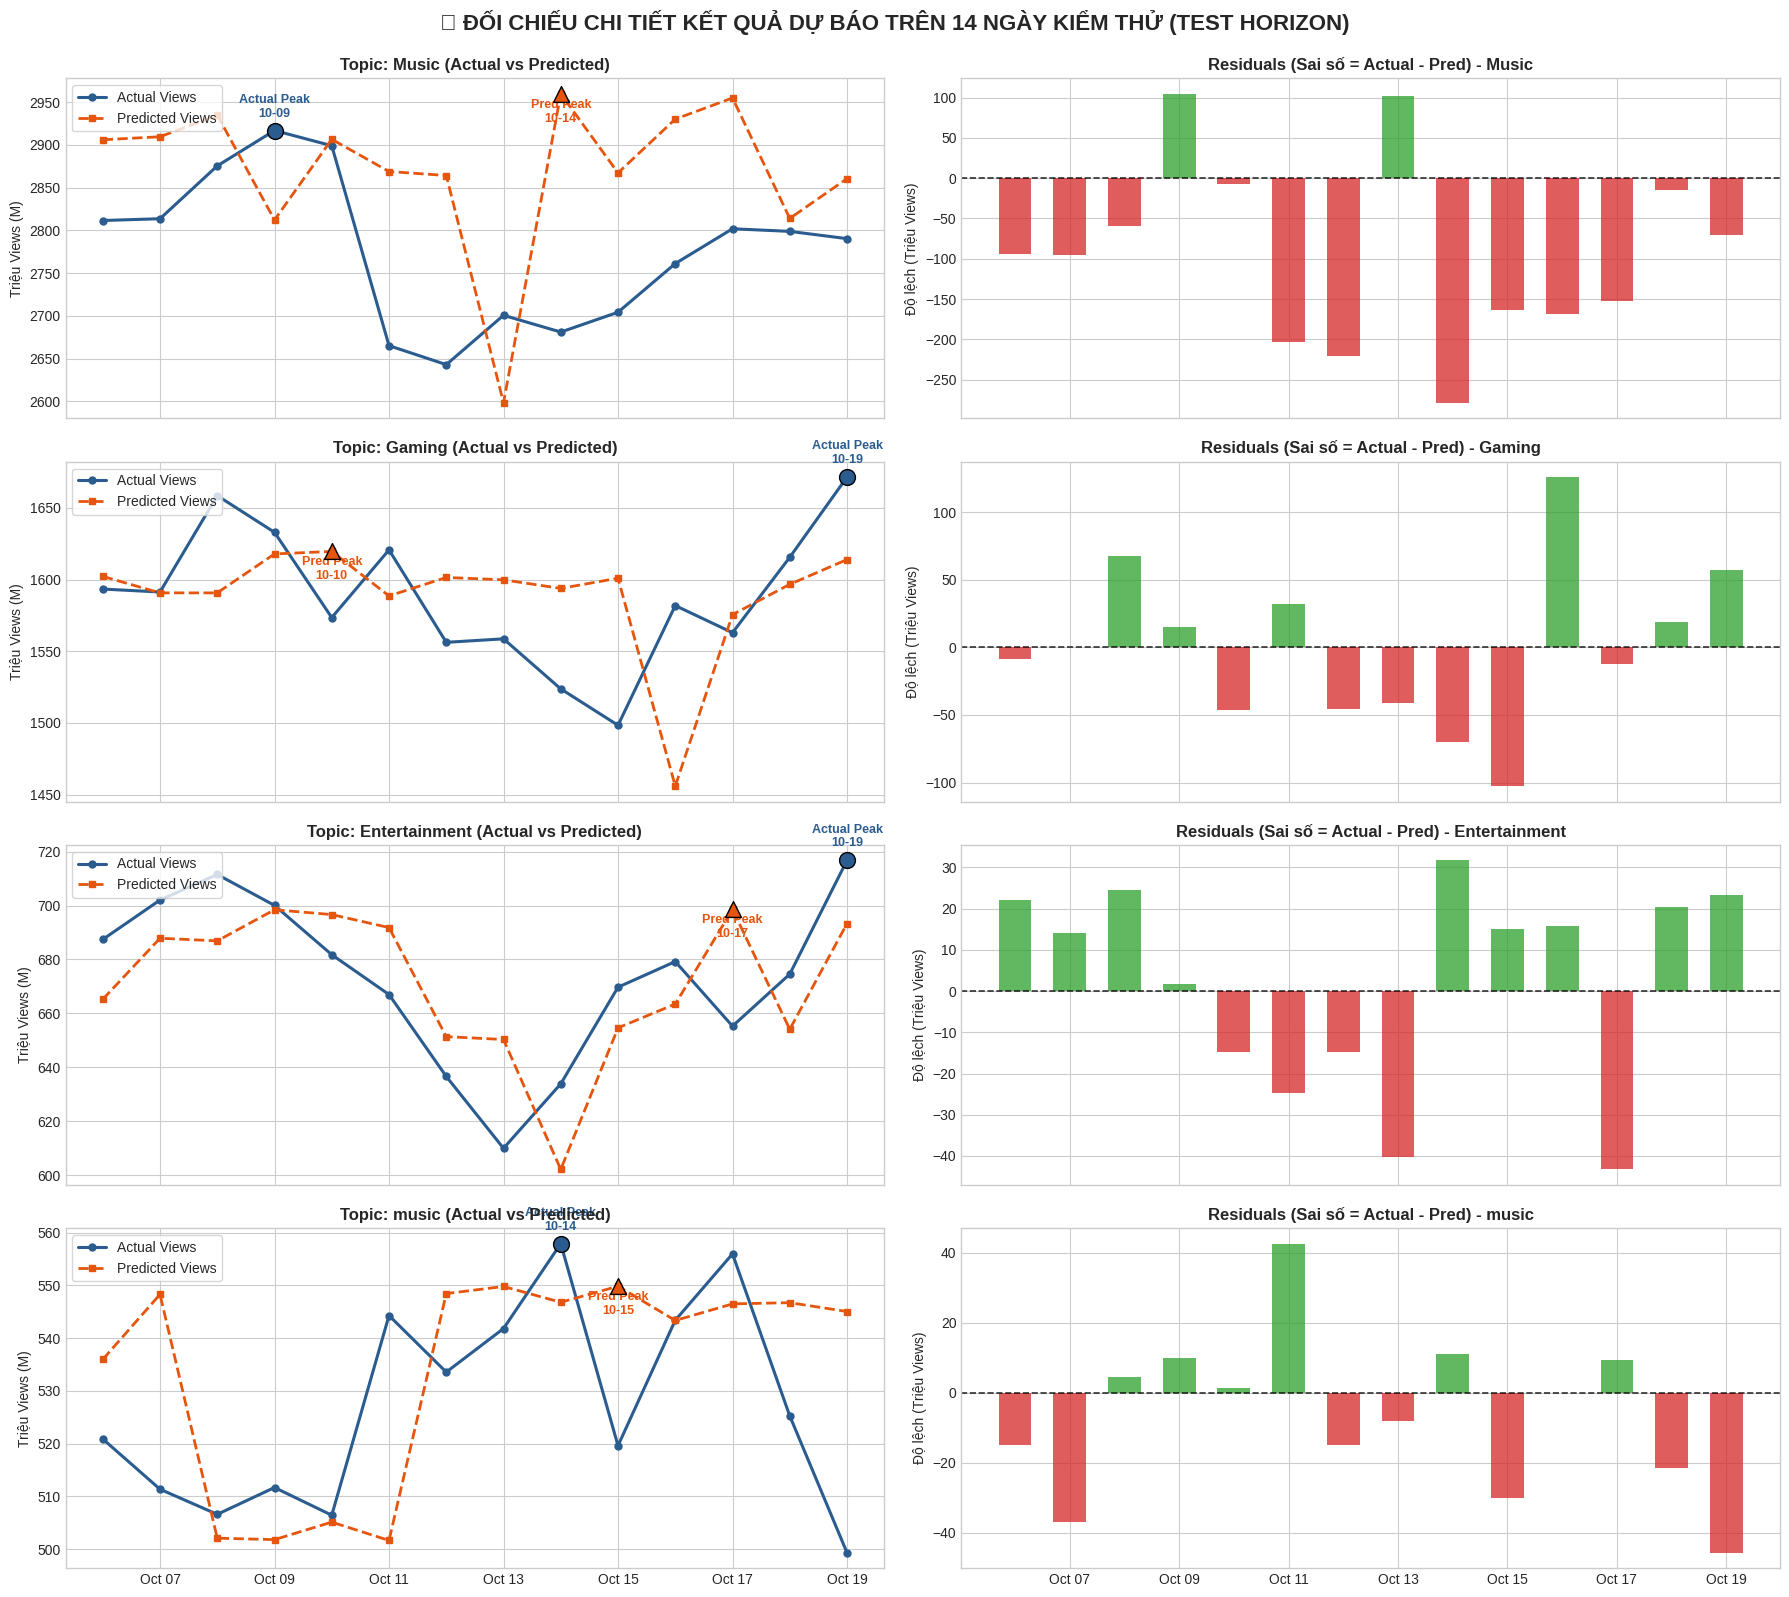

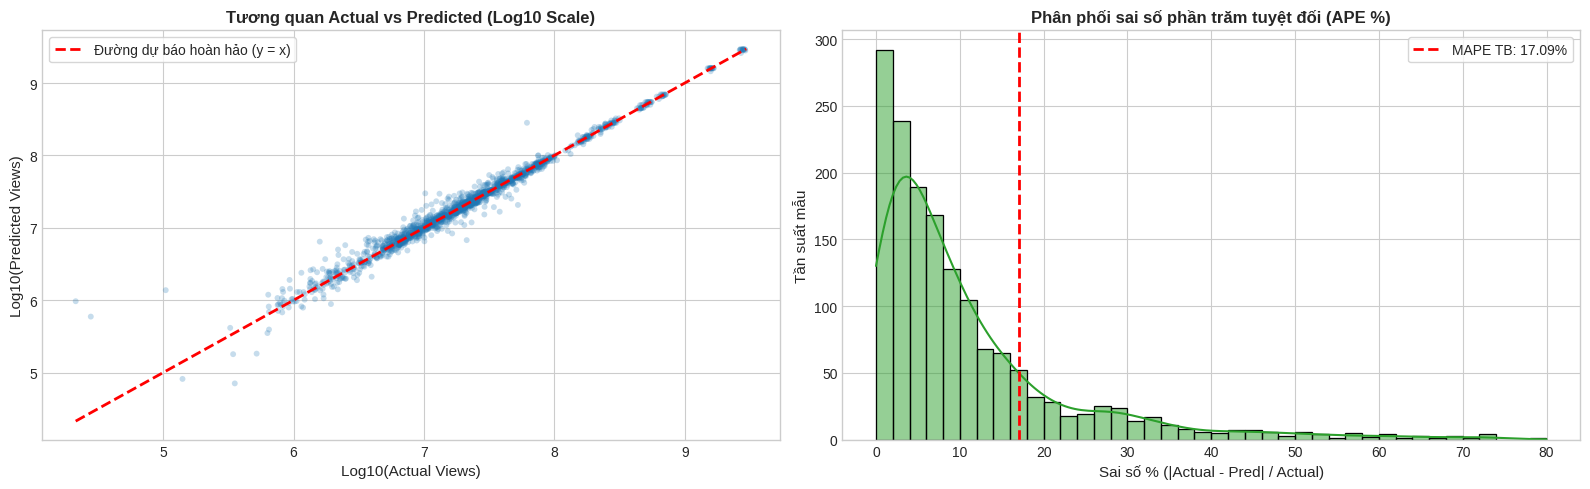

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Thiết lập phong cách hiển thị
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig_palette = ["#1f77b4", "#ff7f0e", "#d62728", "#2ca02c"]

# 1. Chọn 4 chủ đề tiêu biểu để vẽ (ưu tiên các category phổ biến hoặc tag có lượng view lớn)
sample_topics = test_df.groupby("topic_name")["actual_views"].mean().nlargest(4).index.tolist()

# ------------------------------------------------------------------------------
# HÌNH 1: ĐỐI CHIẾU THỰC TẾ VS DỰ BÁO & BIỂU ĐỒ RESIDUALS (SAI SỐ DỰ BÁO)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(18, 16), sharex='col')
plt.subplots_adjust(hspace=0.28, wspace=0.18)

for i, topic in enumerate(sample_topics):
    sub = test_df[test_df["topic_name"] == topic].sort_values("ds").copy()
    sub["residual"] = sub["actual_views"] - sub["pred_views"]

    # Tìm đỉnh thực tế và đỉnh dự đoán
    actual_peak = sub.loc[sub["actual_views"].idxmax()]
    pred_peak = sub.loc[sub["pred_views"].idxmax()]

    # Cột trái: Actual vs Predicted
    ax_main = axes[i, 0]
    ax_main.plot(sub["ds"], sub["actual_views"] / 1e6, label="Actual Views", color="#2b5c8f", marker="o", linewidth=2.2, markersize=5)
    ax_main.plot(sub["ds"], sub["pred_views"] / 1e6, label="Predicted Views", color="#e6550d", marker="s", linestyle="--", linewidth=2, markersize=5)

    # Đánh dấu đỉnh (Peak)
    ax_main.scatter(actual_peak["ds"], actual_peak["actual_views"] / 1e6, color="#2b5c8f", s=130, edgecolor="black", zorder=5)
    ax_main.scatter(pred_peak["ds"], pred_peak["pred_views"] / 1e6, color="#e6550d", s=130, marker="^", edgecolor="black", zorder=5)
    ax_main.annotate(f"Actual Peak\n{actual_peak['ds'].strftime('%m-%d')}",
                     (actual_peak["ds"], actual_peak["actual_views"] / 1e6),
                     textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, fontweight='bold', color="#2b5c8f")
    ax_main.annotate(f"Pred Peak\n{pred_peak['ds'].strftime('%m-%d')}",
                     (pred_peak["ds"], pred_peak["pred_views"] / 1e6),
                     textcoords="offset points", xytext=(0, -20), ha='center', fontsize=9, fontweight='bold', color="#e6550d")

    ax_main.set_title(f"Topic: {topic} (Actual vs Predicted)", fontsize=12, fontweight='bold')
    ax_main.set_ylabel("Triệu Views (M)", fontsize=10)
    ax_main.legend(loc="upper left", frameon=True)
    ax_main.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

    # Cột phải: Biểu đồ sai số Residuals (Actual - Predicted)
    ax_res = axes[i, 1]
    colors = ["#2ca02c" if r >= 0 else "#d62728" for r in sub["residual"]]
    ax_res.bar(sub["ds"], sub["residual"] / 1e6, color=colors, alpha=0.75, width=0.6, edgecolor="none")
    ax_res.axhline(0, color="black", linestyle="--", linewidth=1.2, alpha=0.8)

    ax_res.set_title(f"Residuals (Sai số = Actual - Pred) - {topic}", fontsize=12, fontweight='bold')
    ax_res.set_ylabel("Độ lệch (Triệu Views)", fontsize=10)
    ax_res.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

fig.suptitle("📊 ĐỐI CHIẾU CHI TIẾT KẾT QUẢ DỰ BÁO TRÊN 14 NGÀY KIỂM THỬ (TEST HORIZON)", fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# HÌNH 2: TỔNG THỂ SAI SỐ TOÀN BỘ DATASET (SCATTER & ERROR DISTRIBUTION)
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Biểu đồ tương quan Actual vs Prediction (Đoán chuẩn sẽ nằm trên đường chéo 45 độ)
eval_mask = test_df["actual_views"] > 1000
log_act = np.log10(test_df.loc[eval_mask, "actual_views"])
log_pred = np.log10(test_df.loc[eval_mask, "pred_views"])

ax1.scatter(log_act, log_pred, alpha=0.25, color="#1f77b4", s=18, edgecolors="none")
min_val, max_val = min(log_act.min(), log_pred.min()), max(log_act.max(), log_pred.max())
ax1.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Đường dự báo hoàn hảo (y = x)")
ax1.set_title("Tương quan Actual vs Predicted (Log10 Scale)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Log10(Actual Views)", fontsize=11)
ax1.set_ylabel("Log10(Predicted Views)", fontsize=11)
ax1.legend(frameon=True)

# 2. Phân phối sai số phần trăm tuyệt đối APE (|Actual - Pred| / Actual)
ape_values = np.abs(test_df.loc[eval_mask, "actual_views"] - test_df.loc[eval_mask, "pred_views"]) / test_df.loc[eval_mask, "actual_views"] * 100
# Lọc ngưỡng hiển thị dưới 80% để zoom cận cảnh phần lớn dữ liệu
sns.histplot(ape_values[ape_values <= 80], bins=40, kde=True, ax=ax2, color="#2ca02c")
ax2.axvline(mape_score, color="red", linestyle="--", linewidth=2, label=f"MAPE TB: {mape_score:.2f}%")
ax2.set_title("Phân phối sai số phần trăm tuyệt đối (APE %)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Sai số % (|Actual - Pred| / Actual)", fontsize=11)
ax2.set_ylabel("Tần suất mẫu", fontsize=11)
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

## HÀM SUY LUẬN DỰ BÁO TƯƠNG LAI (RECURSIVE MULTI-STEP FORECASTING)

In [6]:
# ==============================================================================
# CELL 5: HÀM SUY LUẬN DỰ BÁO TƯƠNG LAI (RECURSIVE MULTI-STEP FORECASTING)
# ==============================================================================
# Đây chính là hàm sẽ được đưa vào Backend Django (src/trainers.py):
# ĐẦU VÀO : Lịch sử của 1 chủ đề (lấy từ file Parquet sạch) + Số ngày muốn dự đoán (VD: 14 ngày tới)
# ĐẦU RA  : Thời điểm đạt đỉnh tiếp theo (next_peak_date), Lượng view đỉnh (peak_views), và chuỗi dự báo từng ngày.

def forecast_topic_future(topic_name: str, history_df: pd.DataFrame, model, topic_map: dict, horizon_days: int = 14) -> dict:
    if topic_name not in topic_map:
        raise ValueError(f"Chủ đề '{topic_name}' không tồn tại trong từ điển mô hình!")

    # Chỉ lấy 60 ngày lịch sử gần nhất của chủ đề đó để làm mồi (Context Window)
    sub_df = history_df[history_df["topic_name"] == topic_name].sort_values("ds").tail(60).copy()
    sub_df["topic_id"] = topic_map[topic_name]

    future_predictions = []
    last_video_supply = sub_df["trending_video_count"].iloc[-1]

    # Dự báo cuốn chiếu đệ quy từng ngày (t+1 -> t+horizon)
    for step in range(1, horizon_days + 1):
        next_date = sub_df["ds"].max() + pd.Timedelta(days=1)
        new_row = pd.DataFrame({
            "ds": [next_date],
            "topic_name": [topic_name],
            "topic_type": [sub_df["topic_type"].iloc[-1]],
            "topic_id": [topic_map[topic_name]],
            "total_views": [np.nan],
            "trending_video_count": [last_video_supply]
        })

        temp_df = pd.concat([sub_df, new_row], ignore_index=True)
        temp_feat = build_features(temp_df)

        # Lấy dòng cuối cùng (ngày đang cần dự đoán) đưa vào model
        X_next = temp_feat.iloc[[-1]][FEATURE_COLS]
        pred_log = float(model.predict(X_next)[0])
        pred_view = float(np.expm1(max(0.0, pred_log)))

        # Cập nhật lại kết quả dự đoán vào lịch sử để làm bàn đạp đoán ngày tiếp theo
        sub_df = pd.concat([sub_df, pd.DataFrame({
            "ds": [next_date],
            "topic_name": [topic_name],
            "topic_type": [sub_df["topic_type"].iloc[-1]],
            "topic_id": [topic_map[topic_name]],
            "total_views": [pred_view],
            "trending_video_count": [last_video_supply]
        })], ignore_index=True)

        future_predictions.append({
            "date": next_date.strftime("%Y-%m-%d"),
            "predicted_views": round(pred_view)
        })

    pred_df = pd.DataFrame(future_predictions)
    peak_row = pred_df.loc[pred_df["predicted_views"].idxmax()]
    avg_recent_views = float(history_df[history_df["topic_name"] == topic_name].tail(14)["total_views"].mean())
    growth_pct = ((peak_row["predicted_views"] - avg_recent_views) / max(1.0, avg_recent_views)) * 100

    return {
        "topic_name": topic_name,
        "forecast_horizon_days": horizon_days,
        "next_peak_date": peak_row["date"],
        "expected_peak_views": int(peak_row["predicted_views"]),
        "expected_total_horizon_views": int(pred_df["predicted_views"].sum()),
        "surge_percentage_vs_last_14d": round(growth_pct, 2),
        "daily_forecast_series": future_predictions
    }

# Chạy thử nghiệm dự báo cho chủ đề "Gaming" (hoặc chủ đề đầu tiên trong danh sách)
sample_topic = "Gaming" if "Gaming" in topic_to_id else topic_list[0]
result_json = forecast_topic_future(sample_topic, df_continuous, lgb_model, topic_to_id, horizon_days=14)
print(f"\n🔮 KẾT QUẢ DỰ BÁO TƯƠNG LAI CHO CHỦ ĐỀ: [{sample_topic}]")
print(json.dumps(result_json, indent=2, ensure_ascii=False))


🔮 KẾT QUẢ DỰ BÁO TƯƠNG LAI CHO CHỦ ĐỀ: [Gaming]
{
  "topic_name": "Gaming",
  "forecast_horizon_days": 14,
  "next_peak_date": "2026-10-20",
  "expected_peak_views": 1618633229,
  "expected_total_horizon_views": 22521258429,
  "surge_percentage_vs_last_14d": 1.9,
  "daily_forecast_series": [
    {
      "date": "2026-10-20",
      "predicted_views": 1618633229
    },
    {
      "date": "2026-10-21",
      "predicted_views": 1611391106
    },
    {
      "date": "2026-10-22",
      "predicted_views": 1593091368
    },
    {
      "date": "2026-10-23",
      "predicted_views": 1599833294
    },
    {
      "date": "2026-10-24",
      "predicted_views": 1603539298
    },
    {
      "date": "2026-10-25",
      "predicted_views": 1609181413
    },
    {
      "date": "2026-10-26",
      "predicted_views": 1613321888
    },
    {
      "date": "2026-10-27",
      "predicted_views": 1611653267
    },
    {
      "date": "2026-10-28",
      "predicted_views": 1610699584
    },
    {
      "

## LƯU TRỌNG SỐ MÔ HÌNH & ĐẨY LÊN HUGGING FACE MODEL HUB

In [7]:
# ==============================================================================
# CELL 6: LƯU TRỌNG SỐ MÔ HÌNH & ĐẨY LÊN HUGGING FACE MODEL HUB
# ==============================================================================
os.makedirs("model_artifacts", exist_ok=True)

# 1. Lưu LightGBM Model (.pkl)
model_path = "model_artifacts/lgbm_trend_forecaster_14day.pkl"
joblib.dump(lgb_model, model_path)

# 2. Lưu Metadata & Từ điển ánh xạ chủ đề (.json) để Server Django đọc
metadata = {
    "feature_columns": FEATURE_COLS,
    "topic_to_id": topic_to_id,
    "metrics": {
        "MAE": round(float(mae_views), 2),
        "RMSE": round(float(rmse_views), 2),
        "MAPE_pct": round(float(mape_score), 2),
        "Peak_Timing_Error_Days": round(float(mean_peak_day_error), 2)
    }
}
meta_path = "model_artifacts/model_metadata.json"
with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("✅ Đã đóng gói Model & Metadata tại thư mục 'model_artifacts/'")

# 3. Upload lên Hugging Face Model Hub
if HF_TOKEN != "hf_YOUR_HUGGINGFACE_WRITE_TOKEN":
    login(token=HF_TOKEN)
    api = HfApi()
    api.create_repo(repo_id=HF_MODEL_REPO, repo_type="model", exist_ok=True)
    api.upload_folder(
        folder_path="model_artifacts",
        repo_id=HF_MODEL_REPO,
        repo_type="model",
        commit_message="Upload LightGBM Trend Forecaster and Topic Metadata"
    )
    print(f"🚀 Đã đẩy Model lên Hugging Face: https://huggingface.co/{HF_MODEL_REPO}")

✅ Đã đóng gói Model & Metadata tại thư mục 'model_artifacts/'
🚀 Đã đẩy Model lên Hugging Face: https://huggingface.co/cuongduongok/yt-trend-forecaster-models
